Loading Native Julia AC-Capable Surrogates... (This only happens once)
Successfully loaded Native Julia LUTs!

>>> Generating 300 circuit configurations...

 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (FOLDED CASCODE OPEN LOOP SINE)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads (Adaptive Time Steps)...
Julia 300-Circuit Transient Total Time: 5.407 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking - Copy\julia_sine_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 30/300 circuits done...
    LTspice progress: 60/300 circuits done...
    LTspice progress: 90/300 circuits done...
    LTspice progress: 120/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 180/300 circuits done...
    LTsp

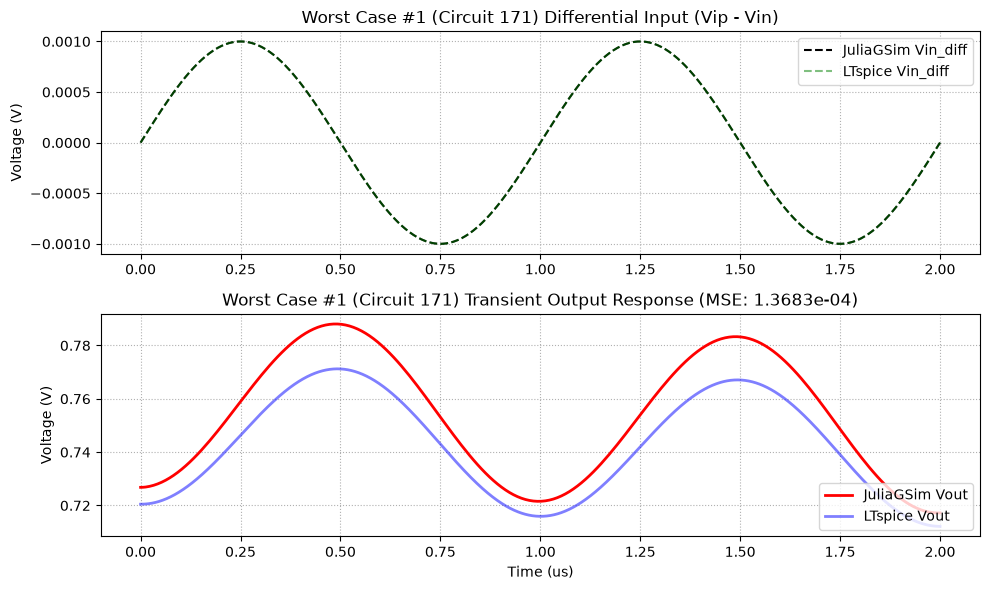


----------------------------------------------------------------------
Worst Case #2 (Circuit 161) - MSE: 1.1558e-04, Gain Error: 1.42 dB
Params: W=31.0um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 32.20       V/V | 27.34       V/V
Gain (dB)       | 30.16       dB  | 28.73       dB 
Gain Difference | 1.42        dB  |



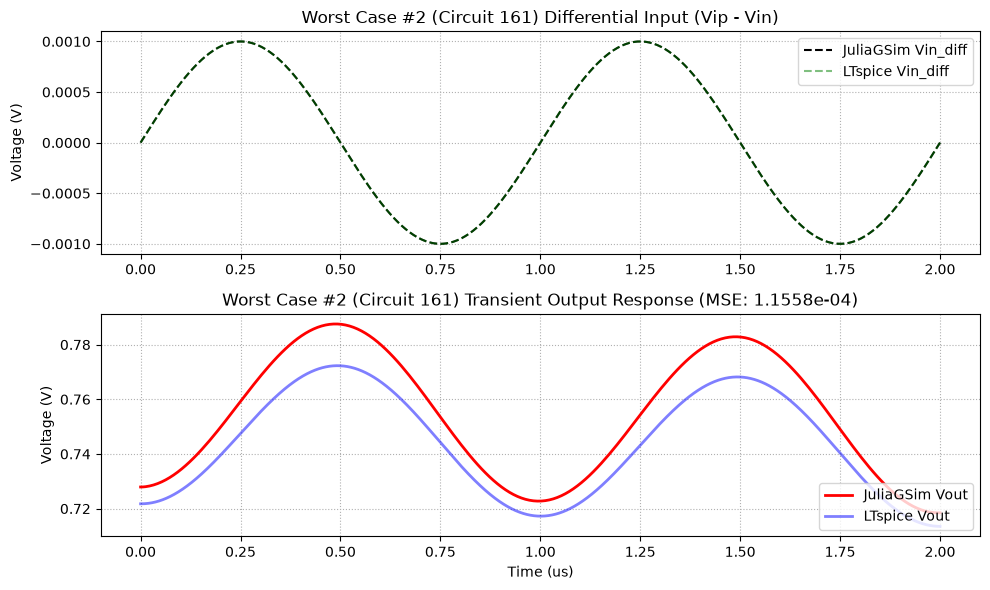


----------------------------------------------------------------------
Worst Case #3 (Circuit 181) - MSE: 1.1300e-04, Gain Error: 1.30 dB
Params: W=32.4um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 32.03       V/V | 27.59       V/V
Gain (dB)       | 30.11       dB  | 28.81       dB 
Gain Difference | 1.30        dB  |



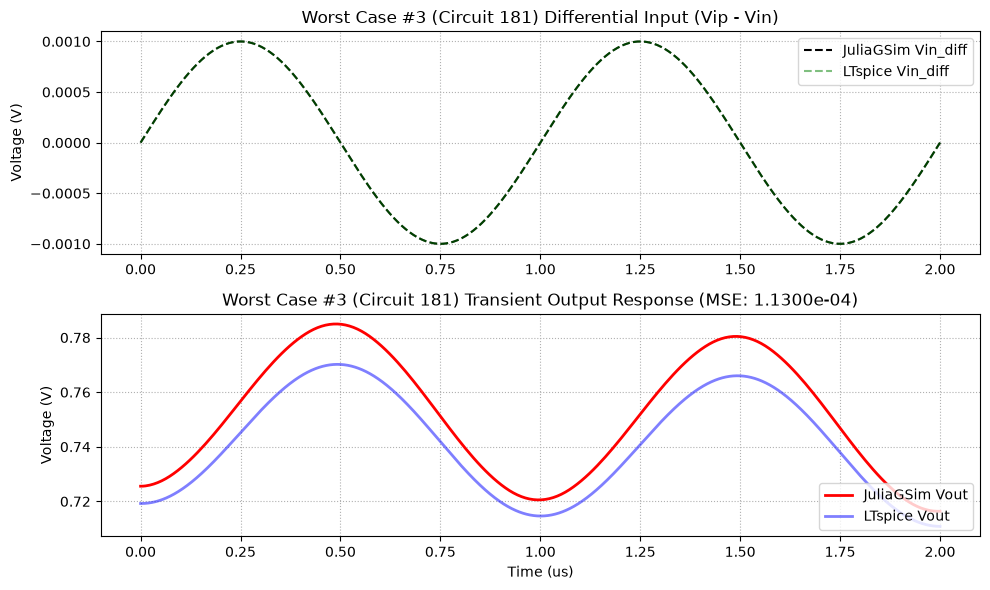


----------------------------------------------------------------------
Worst Case #4 (Circuit 151) - MSE: 9.6750e-05, Gain Error: 1.23 dB
Params: W=30.3um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 31.34       V/V | 27.21       V/V
Gain (dB)       | 29.92       dB  | 28.69       dB 
Gain Difference | 1.23        dB  |



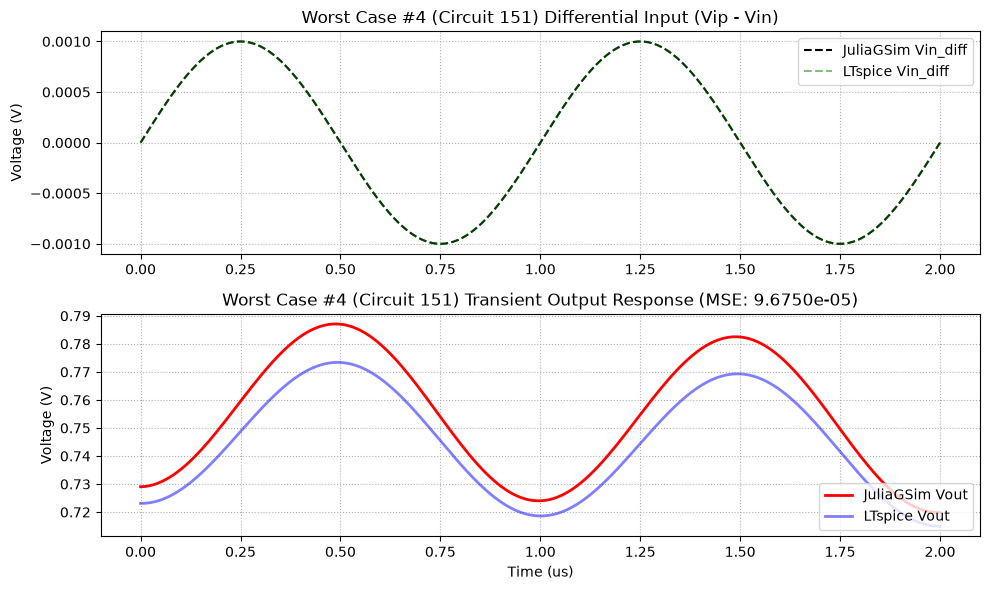


----------------------------------------------------------------------
Worst Case #5 (Circuit 141) - MSE: 7.9962e-05, Gain Error: 1.03 dB
Params: W=29.7um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 30.50       V/V | 27.07       V/V
Gain (dB)       | 29.68       dB  | 28.65       dB 
Gain Difference | 1.03        dB  |



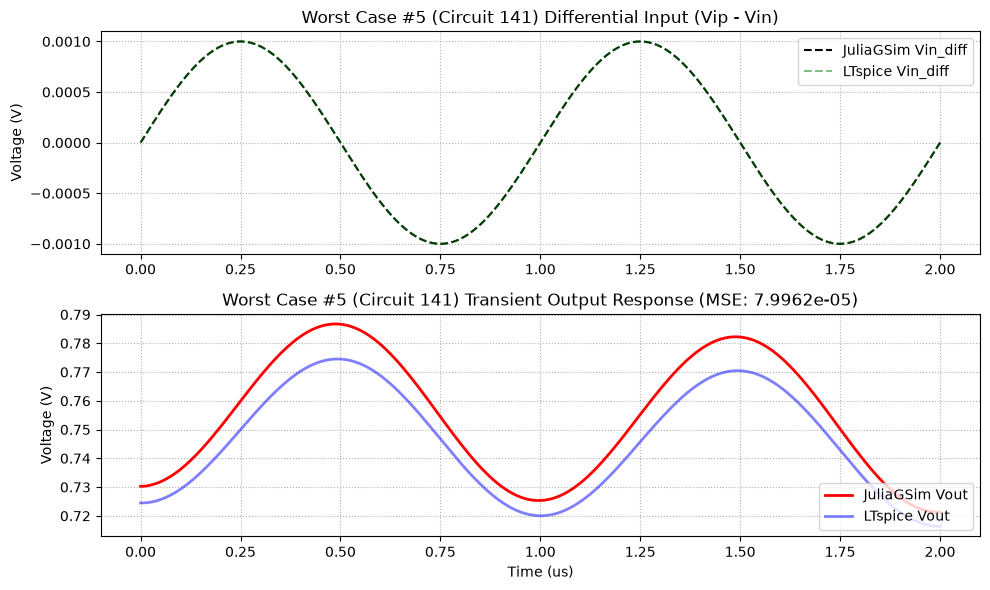


----------------------------------------------------------------------
Worst Case #6 (Circuit 292) - MSE: 6.6506e-05, Gain Error: 0.93 dB
Params: W=40.0um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 24.96       V/V | 22.42       V/V
Gain (dB)       | 27.94       dB  | 27.01       dB 
Gain Difference | 0.93        dB  |



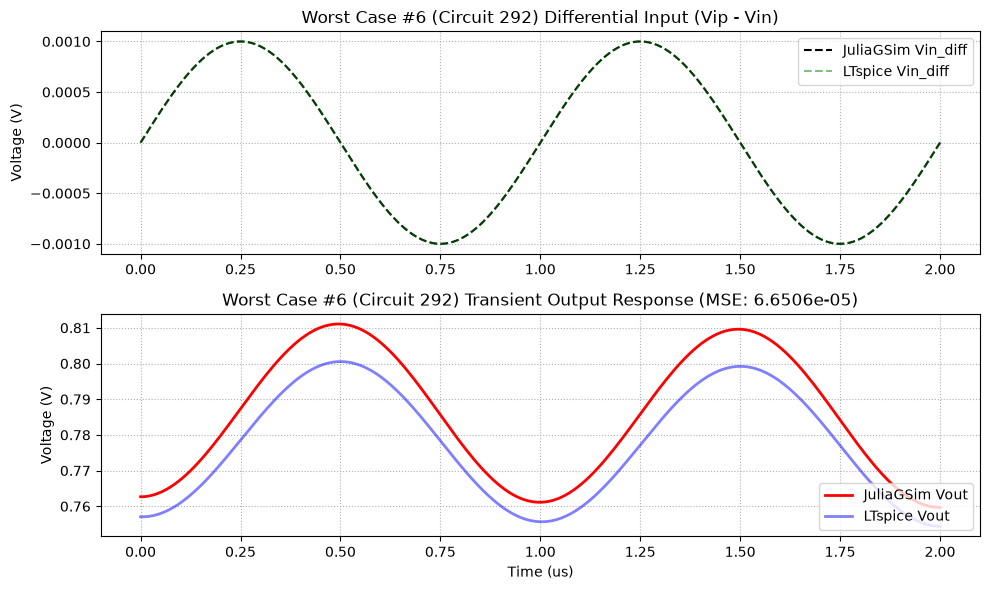


----------------------------------------------------------------------
Worst Case #7 (Circuit 131) - MSE: 6.5174e-05, Gain Error: 0.84 dB
Params: W=29.0um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 29.66       V/V | 26.93       V/V
Gain (dB)       | 29.44       dB  | 28.61       dB 
Gain Difference | 0.84        dB  |



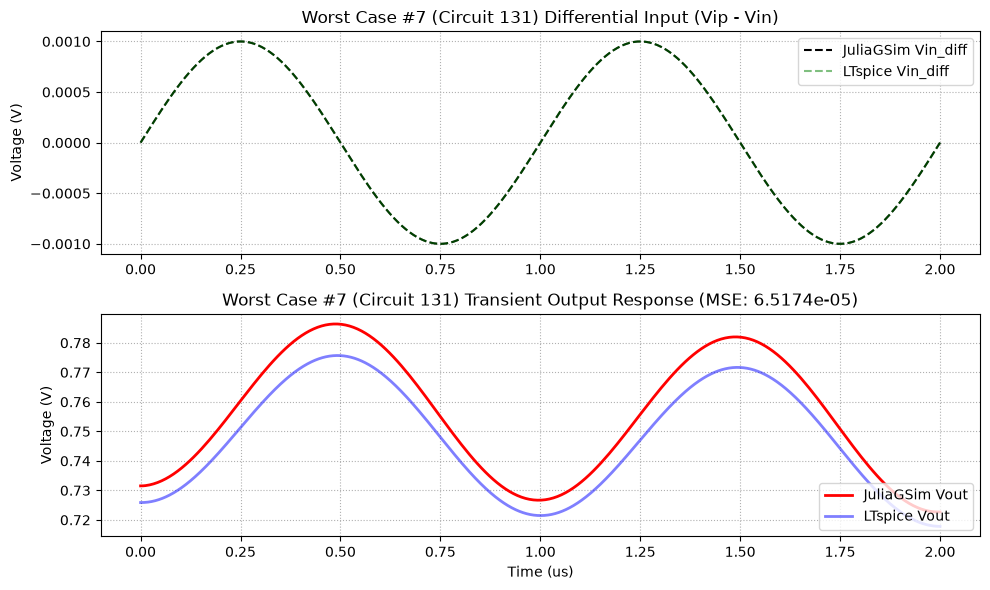


----------------------------------------------------------------------
Worst Case #8 (Circuit 282) - MSE: 6.0323e-05, Gain Error: 0.79 dB
Params: W=39.3um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 24.47       V/V | 22.34       V/V
Gain (dB)       | 27.77       dB  | 26.98       dB 
Gain Difference | 0.79        dB  |



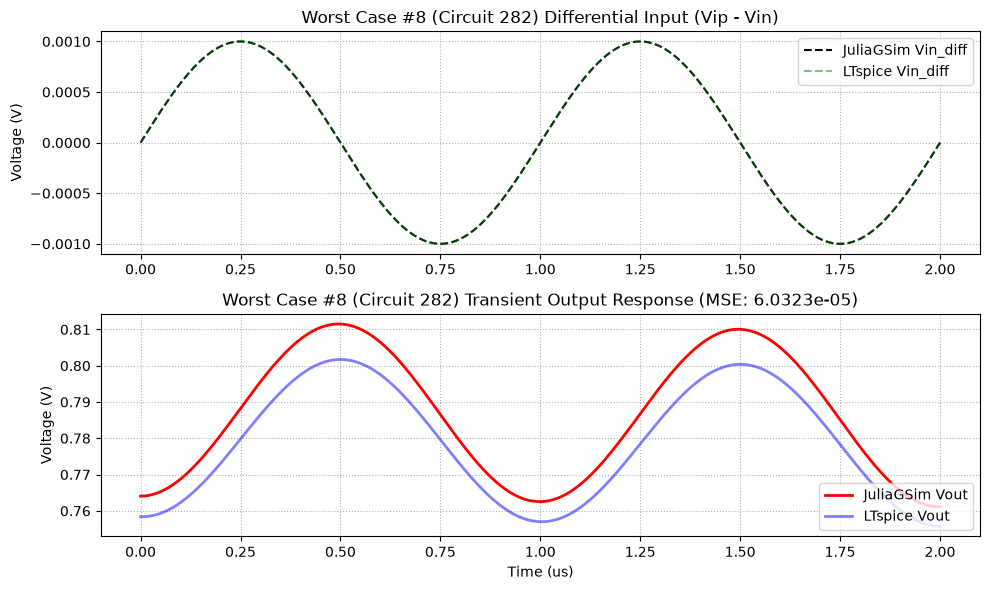


----------------------------------------------------------------------
Worst Case #9 (Circuit 262) - MSE: 5.7593e-05, Gain Error: 0.70 dB
Params: W=37.9um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 24.02       V/V | 22.17       V/V
Gain (dB)       | 27.61       dB  | 26.91       dB 
Gain Difference | 0.70        dB  |



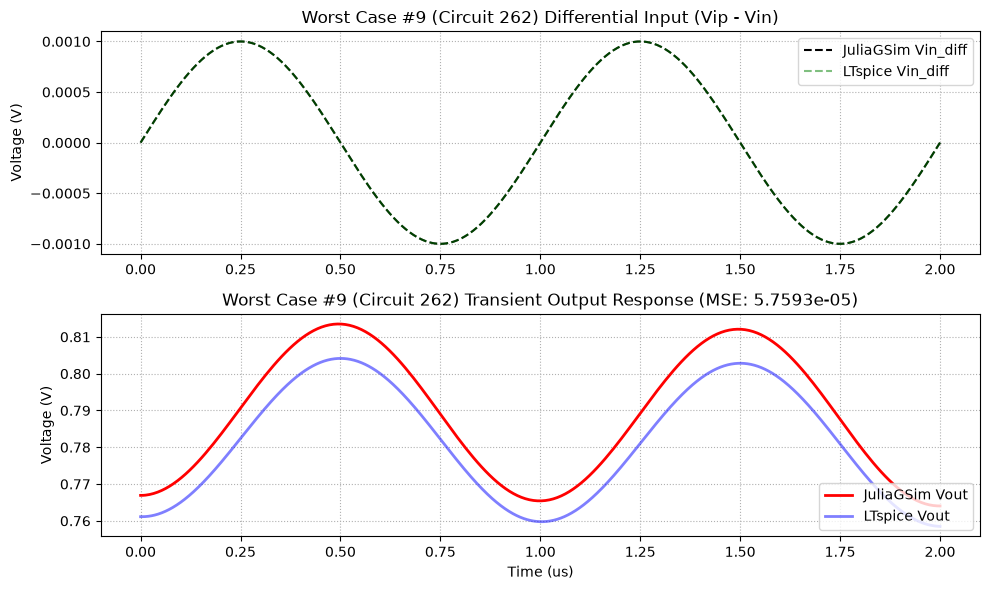


----------------------------------------------------------------------
Worst Case #10 (Circuit 272) - MSE: 5.5177e-05, Gain Error: 0.65 dB
Params: W=38.6um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Gain (Linear)   | 23.98       V/V | 22.25       V/V
Gain (dB)       | 27.60       dB  | 26.95       dB 
Gain Difference | 0.65        dB  |



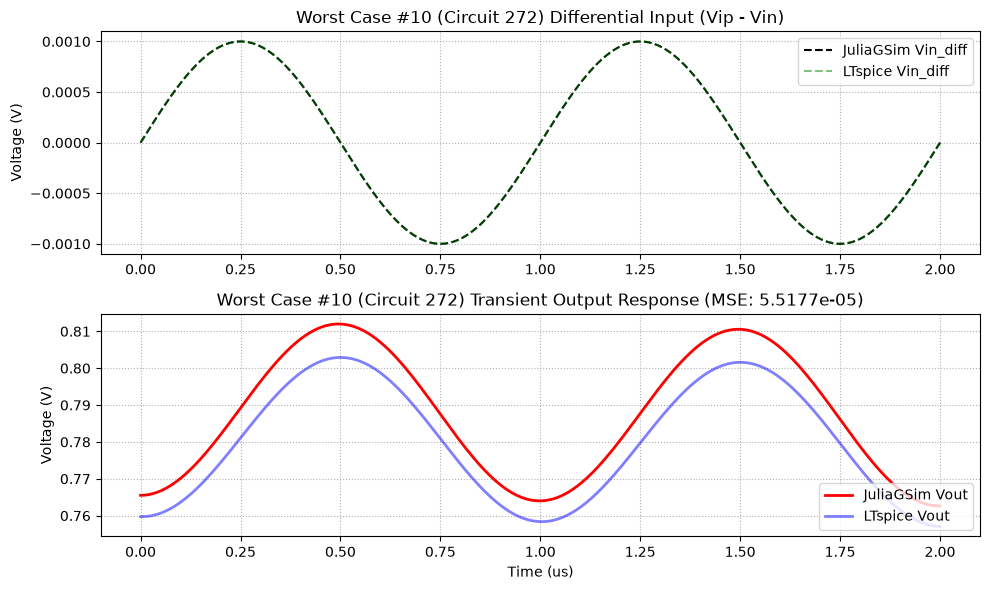

In [1]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim_Finalized.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH 
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_fc_tran(md, Ld, mp_src, Lp, mss, Lss, mp_csc, mm_mir, mm_csc, Lm, mb, Ib, I_cascode, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    m_bias_p_csc = mp_csc / 4.0
    m_bias_n_csc = mm_csc / 4.0
    I_tail = Ib * (mss/mb)
    I_pmos = I_tail/2.0 + I_cascode
    
    netlist = f'''* NMOS-Input Folded Cascode OTA Open Loop Sine Testbench
Vdd Vdd 0 3

VCM vicm 0  2
VDMP vip vicm SINE(0 0.5m 1Meg)
VDMN vin vicm SINE(0 -0.5m 1Meg)

IB Vdd vb {Ib}

I_Vbp Vbp 0 {I_pmos}
I_VcscP VcscP 0 {I_cascode}
I_VcscN Vdd VcscN {I_cascode}

M_bias vb vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mb}
M_bias_p Vbp Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M_bias_cscP VcscP VcscP Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={m_bias_p_csc}
M_bias_cscN VcscN VcscN 0 0 nmos_3p3 l={Lm} w=0.5u m={m_bias_n_csc}

M_tail vT vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mss}
M1 vfold_p vip vT 0 nmos_3p3 l={Ld} w=0.5u m={md}
M2 vfold_n vin vT 0 nmos_3p3 l={Ld} w=0.5u m={md}

M3 vfold_p Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M4 vfold_n Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}

M5 vx_left VcscP vfold_p Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}
M6 vout VcscP vfold_n Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}

M7 vy_left vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}
M8 vout_bot vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}

M9 vx_left VcscN vy_left 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}
M10 vout VcscN vout_bot 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}

CL vout 0 {CL}

.model NMOS NMOS
.model PMOS PMOS
.inc cmos_tt.txt
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}

.options plotwinsize=0 method=gear
.tran 0 2u 0 1n
* MEASUREMENTS
.meas tran voutcm AVG V(vout) FROM=1u TO=2u
.meas tran vin_max MAX V(vip,vin) FROM=1u TO=2u
.meas tran vin_min MIN V(vip,vin) FROM=1u TO=2u
.meas tran vin_diff_pk_pk PARAM vin_max-vin_min
.meas tran vout_max MAX V(vout) FROM=1u TO=2u
.meas tran vout_min MIN V(vout) FROM=1u TO=2u
.meas tran vout_diff_pk_pk PARAM vout_max-vout_min
.meas tran gain PARAM vout_diff_pk_pk/vin_diff_pk_pk
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_fc_open.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_fc_open.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_fc_open.log")
    
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: f.write(netlist)
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    vout = raw.get_trace("V(vout)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    vin = raw.get_trace("V(vin)").get_wave(0)
    
    gain = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('gain:'):
                    try: gain = float(line.split('=')[1].strip())
                    except: pass
    return t, vip, vin, vout, gain
""", g)
run_ltspice_fc_tran = g["run_ltspice_fc_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    md::Float64; mp_src::Float64; mss::Float64; mp_csc::Float64
    mm_mir::Float64; mm_csc::Float64; mb::Float64
    m_bias_p_csc::Float64; m_bias_n_csc::Float64
    Ld::Float64; Lm::Float64; Lss::Float64; Lp::Float64
    I_pmos_val::Float64
end

VDD = 3.0
Ib, I_cascode = 20e-6, 20e-6
CL = 1e-12

W_arr = range(20e-6, stop=40e-6, length=30)
L_arr = range(1e-6, stop=10e-6, length=10)
W_flat = Float64[]
L_flat = Float64[]
for w in W_arr, l in L_arr
    push!(W_flat, w)
    push!(L_flat, l)
end
N_batch = length(W_flat) # 300 circuits

println("\n>>> Generating $(N_batch) circuit configurations...")

M_unit = 0.5e-6
md_np = W_flat ./ M_unit
mp_src_np = W_flat ./ M_unit
mss_np = W_flat ./ M_unit
mp_csc_np = (2.5 .* W_flat) ./ M_unit
mm_mir_np = (0.5 .* W_flat) ./ M_unit
mm_csc_np = (0.5 .* W_flat) ./ M_unit
mb_np = (0.5 .* W_flat) ./ M_unit

Ld_np = L_flat
Lm_np = L_flat
Lss_np = L_flat
Lp_np = 0.5 .* L_flat

m_bias_p_csc_np = mp_csc_np ./ 4.0
m_bias_n_csc_np = mm_csc_np ./ 4.0

circuits = Vector{CircuitParams}(undef, N_batch)
for i in 1:N_batch
    I_tail_val = Ib * (mss_np[i]/mb_np[i])
    I_pmos_val = I_tail_val / 2.0 + I_cascode
    
    circuits[i] = CircuitParams(
        md_np[i], mp_src_np[i], mss_np[i], mp_csc_np[i], 
        mm_mir_np[i], mm_csc_np[i], mb_np[i], 
        m_bias_p_csc_np[i], m_bias_n_csc_np[i], 
        Ld_np[i], Lm_np[i], Lss_np[i], Lp_np[i], I_pmos_val
    )
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N_batch) CIRCUITS (FOLDED CASCODE OPEN LOOP SINE)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V_VDD", "VDD", "0", VDD)

# Equivalent to VCM (2.0V) + SINE differential drive
sine_p = make_sine(2.0, 0.5e-3, 1e6, 0.0, 0.0, 0.0)
sine_n = make_sine(2.0, -0.5e-3, 1e6, 0.0, 0.0, 0.0)
add_vsource!(sim_tran, "V_VIP", "vip", "0", sine_p)
add_vsource!(sim_tran, "V_VIN", "vin", "0", sine_n)

add_isource!(sim_tran, "IB", "VDD", "vb", Ib)
add_isource!(sim_tran, "I_Vbp", "Vbp", "0", :I_pmos_val)
add_isource!(sim_tran, "I_VcscP", "VcscP", "0", I_cascode)
add_isource!(sim_tran, "I_VcscN", "VDD", "VcscN", I_cascode)

add_nmos!(sim_tran, "M_bias", d="vb", g="vb", s="0", b="0", M=:mb, L=:Lss)
add_pmos!(sim_tran, "M_bias_p", d="Vbp", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M_bias_cscP", d="VcscP", g="VcscP", s="VDD", b="VDD", M=:m_bias_p_csc, L=:Lp)
add_nmos!(sim_tran, "M_bias_cscN", d="VcscN", g="VcscN", s="0", b="0", M=:m_bias_n_csc, L=:Lm)

add_nmos!(sim_tran, "M_tail", d="vT", g="vb", s="0", b="0", M=:mss, L=:Lss)
add_nmos!(sim_tran, "M1", d="vfold_p", g="vip", s="vT", b="0", M=:md, L=:Ld)
add_nmos!(sim_tran, "M2", d="vfold_n", g="vin", s="vT", b="0", M=:md, L=:Ld)

add_pmos!(sim_tran, "M3", d="vfold_p", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M4", d="vfold_n", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M5", d="vx_left", g="VcscP", s="vfold_p", b="VDD", M=:mp_csc, L=:Lp)
add_pmos!(sim_tran, "M6", d="vout", g="VcscP", s="vfold_n", b="VDD", M=:mp_csc, L=:Lp)

add_nmos!(sim_tran, "M7", d="vy_left", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M8", d="vout_bot", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M9", d="vx_left", g="VcscN", s="vy_left", b="0", M=:mm_csc, L=:Lm)
add_nmos!(sim_tran, "M10", d="vout", g="VcscN", s="vout_bot", b="0", M=:mm_csc, L=:Lm)

add_cap!(sim_tran, "CL", "vout", "0", CL)
compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N_batch)-Batch Transient Solves on $(nthreads()) Julia Threads (Adaptive Time Steps)...")

t_stop, dt_init = 2e-6, 0.1e-9
results_x_hist = Vector{Matrix{Float64}}(undef, N_batch)
results_t_hist = Vector{Vector{Float64}}(undef, N_batch)

start_time = time()
@threads for i in 1:N_batch
    t_hist, x_hist = solve_tran(sim_tran, circuits[i], t_stop, dt_init)
    results_x_hist[i] = x_hist
    results_t_hist[i] = t_hist
end
total_time = time() - start_time

println("Julia $(N_batch)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_sine_cache_$(N_batch).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_vout = findfirst(==("vout"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N_batch)
spice_vouts = Vector{Any}(undef, N_batch)
spice_vips  = Vector{Any}(undef, N_batch)
spice_vins  = Vector{Any}(undef, N_batch)
spice_gains = zeros(N_batch)

start_spice = time()
for i in 1:N_batch
    t_lt, vip_lt, vin_lt, vout_lt, gain_lt = run_ltspice_fc_tran(
        circuits[i].md, circuits[i].Ld, circuits[i].mp_src, circuits[i].Lp,
        circuits[i].mss, circuits[i].Lss, circuits[i].mp_csc, circuits[i].mm_mir,
        circuits[i].mm_csc, circuits[i].Lm, circuits[i].mb, Ib, I_cascode, CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_vouts[i] = pyconvert(Array, vout_lt)
    spice_vips[i]  = pyconvert(Array, vip_lt)
    spice_vins[i]  = pyconvert(Array, vin_lt)
    spice_gains[i] = pyconvert(Float64, gain_lt)
    if i % 30 == 0; println("    LTspice progress: $i/$N_batch circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_sine_cache_$(N_batch).jld2")
@save spice_cache_file spice_times spice_vouts spice_vips spice_vins spice_gains spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. GAIN & MSE CALCULATION & 10 WORST-CASE WAVEFORM PLOTTING
# ==============================================================================
println(">>> Calculating Gain and Waveform MSE for all $(N_batch) circuits...")
errors = Tuple{Float64, Float64, Float64, Float64, Int}[] # (mse, gain_jl, gain_spice, gain_err_dB, circuit_index)

julia_gains = zeros(N_batch)
gain_errors_dB = zeros(N_batch)

for i in 1:N_batch
    vout_jl = results_x_hist[i][idx_vout, :]
    times_jl_arr = results_t_hist[i]
    vip_jl = [sine_p(t) for t in times_jl_arr]
    vin_jl = [sine_n(t) for t in times_jl_arr]
    
    idx_1u = findfirst(>=(1e-6), times_jl_arr)
    idx_2u = findfirst(>=(2e-6), times_jl_arr)
    if idx_1u === nothing; idx_1u = 1; end
    if idx_2u === nothing; idx_2u = length(times_jl_arr); end

    v_out_steady = vout_jl[idx_1u:idx_2u]
    v_ip_steady = vip_jl[idx_1u:idx_2u]
    v_in_steady = vin_jl[idx_1u:idx_2u]
    v_diff_in_steady = v_ip_steady .- v_in_steady

    vin_max = maximum(v_diff_in_steady)
    vin_min = minimum(v_diff_in_steady)
    vin_diff_pk_pk = vin_max - vin_min

    vout_max = maximum(v_out_steady)
    vout_min = minimum(v_out_steady)
    vout_diff_pk_pk = vout_max - vout_min

    gain_jl = vout_diff_pk_pk / vin_diff_pk_pk
    gain_dB_jl = 20 * log10(abs(gain_jl) + 1e-12)
    gain_dB_spice = 20 * log10(abs(spice_gains[i]) + 1e-12)
    gain_err_dB = abs(gain_dB_jl - gain_dB_spice)

    julia_gains[i] = gain_jl
    gain_errors_dB[i] = gain_err_dB

    # Waveform MSE
    interp_linear = linear_interpolation(times_jl_arr, vout_jl, extrapolation_bc=Line())
    v_jl_interp = interp_linear.(spice_times[i])
    mse = mean((v_jl_interp .- spice_vouts[i]).^2)

    push!(errors, (mse, gain_jl, spice_gains[i], gain_err_dB, i))
end

sort!(errors, by = x -> x[1], rev=true) # Sorted by highest MSE
worst_10 = errors[1:min(10, length(errors))]

println("======================================================================")
println(" OVERALL ACCURACY STATISTICAL SUMMARY ($(N_batch) CIRCUITS)")
println("======================================================================")
@printf(" Max Waveform MSE        : %.4e V^2\n", errors[1][1])
@printf(" Mean Waveform MSE       : %.4e V^2\n", mean([e[1] for e in errors]))
@printf(" Max Gain Discrepancy    : %.2f dB\n", maximum(gain_errors_dB))
@printf(" Mean Gain Discrepancy   : %.2f dB\n", mean(gain_errors_dB))
println("======================================================================\n")

plt = pyimport("matplotlib.pyplot")
println("======================================================================")
println(" DETAILED RESULTS FOR 10 WORST-CASE CIRCUITS (HIGHEST MSE)")
println("======================================================================\n")

for (idx, (mse, g_jl, g_sp, g_err_db, i)) in enumerate(worst_10)
    vout_jl = results_x_hist[i][idx_vout, :]
    times_jl_arr = results_t_hist[i]
    vip_jl = [sine_p(t) for t in times_jl_arr]
    vin_jl = [sine_n(t) for t in times_jl_arr]

    g_db_jl = 20 * log10(abs(g_jl) + 1e-12)
    g_db_sp = 20 * log10(abs(g_sp) + 1e-12)

    println(repeat("-", 70))
    println("Worst Case #$(idx) (Circuit $i) - MSE: $(@sprintf("%.4e", mse)), Gain Error: $(@sprintf("%.2f", g_err_db)) dB")
    println("Params: W=$(round(W_flat[i]*1e6, digits=1))um, L=$(round(L_flat[i]*1e6, digits=1))um")
    println(repeat("-", 70))
    
    @printf("%-15s | %-15s | %-15s\n", "Metric", "JuliaGSim", "LTspice")
    println(repeat("-", 50))
    @printf("%-15s | %-11.2f V/V | %-11.2f V/V\n", "Gain (Linear)", g_jl, g_sp)
    @printf("%-15s | %-11.2f dB  | %-11.2f dB \n", "Gain (dB)", g_db_jl, g_db_sp)
    @printf("%-15s | %-11.2f dB  |\n", "Gain Difference", g_err_db)
    println()

    # Create figure with 2 subplots
    fig = plt.figure(figsize=(10, 6))
    
    plt.subplot(2, 1, 1)
    plt.plot(times_jl_arr .* 1e6, vip_jl .- vin_jl, "k--", label="JuliaGSim Vin_diff")
    plt.plot(spice_times[i] .* 1e6, spice_vips[i] .- spice_vins[i], "g--", alpha=0.5, label="LTspice Vin_diff")
    plt.title("Worst Case #$(idx) (Circuit $i) Differential Input (Vip - Vin)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    
    plt.subplot(2, 1, 2)
    plt.plot(times_jl_arr .* 1e6, vout_jl, "r-", linewidth=2, label="JuliaGSim Vout")
    plt.plot(spice_times[i] .* 1e6, spice_vouts[i], "b-", alpha=0.5, linewidth=2, label="LTspice Vout")
    plt.title("Worst Case #$(idx) (Circuit $i) Transient Output Response (MSE: $(@sprintf("%.4e", mse)))")
    plt.xlabel("Time (us)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="lower right")
    plt.grid(true, which="both", ls=":")
    
    plt.tight_layout()
    
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    png_data = pyconvert(Vector{UInt8}, buf.getvalue())
    display(MIME("image/png"), png_data)
    plt.close(fig) 
    println()
end
